In [3]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [22]:
df = pd.read_csv('data.csv')
df.sample(5, random_state=42)

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Target,Price_Target
521,41.0,73315.0,57252,3.8,93298.0,4.0,157109.0,2215,20.8,Dhaka,Unknown,A,Type1,NaN,S,Male,0,223.00
737,46.0,178787.0,55297,4.8,126876.0,0.0,419358.0,1092,28.7,Dhaka,C,A,Type2,NaN,S,Female,0,233.71
740,NaN,6057.0,66301,3.3,40303.0,1.0,314431.0,2628,21.9,Dhaka,Unknown,C,Type1,NaN,C,Female,0,256.23
660,28.0,51440.0,64413,3.4,NaN,2.0,270048.0,2261,25.5,Chittagong,Unknown,B,Type2,NaN,C,Male,0,236.42
411,21.0,12169.0,60287,2.0,35858.0,0.0,NaN,1717,22.0,Chittagong,A,C,Type3,NaN,S,Male,0,322.29


Problem 1

```python
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

df = pd.read_csv('data.csv')
imputer = SimpleImputer(strategy='median')
df[['Age', 'Salary']] = imputer.fit_transform(df[['Age', 'Salary']])
X = df.drop('Target', axis=1)
y = df['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
```

**Question:** Identify the data leakage issue. Explain why it is wrong and write the corrected code.

In [81]:
# issue is order. first we have to split and then train

In [9]:
x = df.drop('Target', axis=1)
y = df['Target']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=20)

In [10]:
imputer = SimpleImputer(strategy='median')
df[['Age', 'Salary']] = imputer.fit_transform(df[['Age', 'Salary']])

Problem 2:

Question: Using the provided data.csv file, write code to find:
1. Total missing values in each column
2. Percentage of missing values per column
3. Which columns have more than 50% missing values?


In [51]:
# total missing values

total_missing_values = df.isnull().sum()
total_missing_values = total_missing_values.sum()
print('total missing values:', total_missing_values)

total missing values: 1712


In [53]:
null_percentage = df.isnull().mean() * 100
print(null_percentage)

Age                       18.0
Income                    15.0
Salary                     0.0
Rating                     8.0
Annual_Income             12.0
Customer_Support_Calls     8.0
House_Price               10.0
Square_Feet                0.0
Temperature                5.0
City                       5.0
Product_Type               0.0
Location                   0.0
Diagnosis                 22.0
Cabin                     68.0
Embarked                   0.2
Gender                     0.0
Target                     0.0
Price_Target               0.0
dtype: float64


In [ ]:
# only cabin column has more than 50% missing values

Problem 3:

Question: Look at the Temperature column in data.csv. It contains:

* Numeric values like 22.5, 18.6
* String 'Unknown'
* NaN values

Write code to handle this column properly before imputation.


In [60]:
df = pd.read_csv('data.csv')

In [ ]:
print(df['Temperature'].dtype) # str

# anything except numbers(unknown) becomes NaN
df['Temperature'] = pd.to_numeric(df['Temperature'], errors='coerce') 
print(df['Temperature'].dtype) # float64

# now it's ready for imputation

str
float64


Problem 4:

Question: For the Diagnosis column in data.csv, implement imputation with:
* Constant strategy using 'Missing' string
* Add a missing indicator column

Write the complete code using SimpleImputer.

In [63]:
df['Diagnosis'].info()

<class 'pandas.Series'>
RangeIndex: 1000 entries, 0 to 999
Series name: Diagnosis
Non-Null Count  Dtype
--------------  -----
780 non-null    str  
dtypes: str(1)
memory usage: 11.9 KB


In [65]:
diagnosis_imputer = SimpleImputer(missing_values=np.nan, strategy='constant', fill_value='Missing', add_indicator=True)

diagnosis_imputer.fit(df[['Diagnosis']])

df[['Diagnosis', 'Diagnosis_imputation_indicator']] = diagnosis_imputer.transform(df[['Diagnosis']])

df.sample(10)

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Target,Price_Target,Diagnosis_imputation_indicator
799,35.0,78716.0,50614,2.5,NaN,2.0,211402.0,2066,20.6,Dhaka,A,C,Type2,Cabin_E,S,Male,1,201.33,False
798,35.0,16923.0,76447,3.6,70293.0,1.0,179397.0,2103,18.2,Chittagong,C,A,Type2,NaN,S,Female,0,164.68,False
570,35.0,2206.0,54460,3.6,80675.0,NaN,139374.0,2323,18.2,Chittagong,A,B,Type1,Cabin_D,S,Female,0,167.70,False
6,53.0,2668.0,57598,3.2,81429.0,3.0,323622.0,1559,24.8,Chittagong,C,C,Type3,NaN,S,Female,1,268.01,False
529,24.0,37783.0,66323,3.8,100148.0,3.0,381798.0,929,25.4,Sylhet,A,A,Type3,NaN,S,Male,0,218.60,False
526,15.0,47727.0,63451,5.2,87367.0,2.0,366253.0,1867,28.2,Rajshahi,B,B,Missing,Cabin_C,S,Female,0,240.12,True
482,15.0,NaN,52437,3.7,NaN,NaN,360988.0,1839,24.1,Khulna,A,A,Type3,Cabin_A,C,Male,0,280.81,False
739,47.0,21501.0,67240,2.6,103607.0,1.0,268017.0,2448,24.4,Dhaka,B,A,Type1,NaN,C,Male,1,276.60,False
414,38.0,8245.0,87065,3.6,81091.0,1.0,176352.0,1670,13.2,Dhaka,B,C,Missing,NaN,C,Female,0,311.00,True
841,43.0,65744.0,70468,4.1,56675.0,1.0,251432.0,2311,27.2,Chittagong,B,B,Type3,NaN,C,Female,0,276.06,False


In [67]:
import seaborn as sns
import matplotlib.pyplot as plt

Problem 5:

Question: Using the Age column from data.csv:
* Calculate mean and median from training data only
* Create two new columns: Age_mean_imputed and Age_median_imputed
* Plot KDE for both to compare distributions

Which one would you choose and why?


<Axes: xlabel='Age', ylabel='Density'>

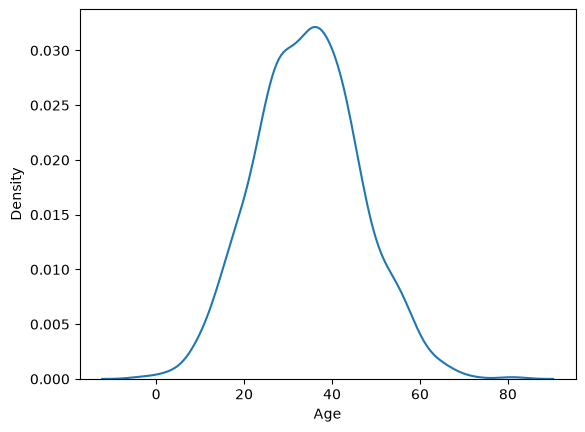

In [68]:
sns.kdeplot(data=df, x='Age')

In [76]:
age_mean_indicator = SimpleImputer(strategy='mean')
age_mean_indicator.fit(df[['Age']])
df['age_mean_imputed'] = age_mean_indicator.transform(df[['Age']])

In [77]:
age_median_indicator = SimpleImputer(strategy='median')
age_median_indicator.fit(df[['Age']])
df['age_median_imputer'] = age_median_indicator.transform(df[['Age']])

<Axes: xlabel='age_mean_imputed', ylabel='Density'>

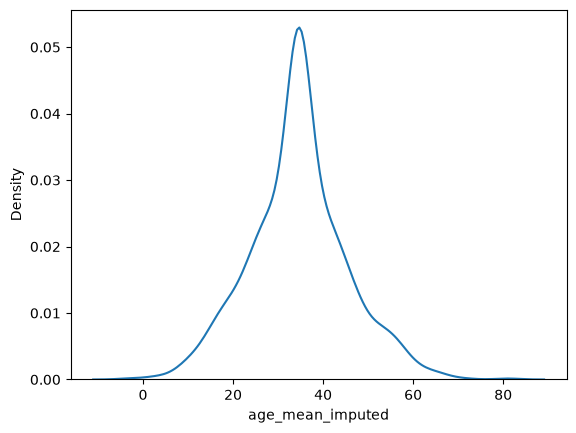

In [79]:
sns.kdeplot(x=df['age_mean_imputed'])

<Axes: xlabel='age_median_imputer', ylabel='Density'>

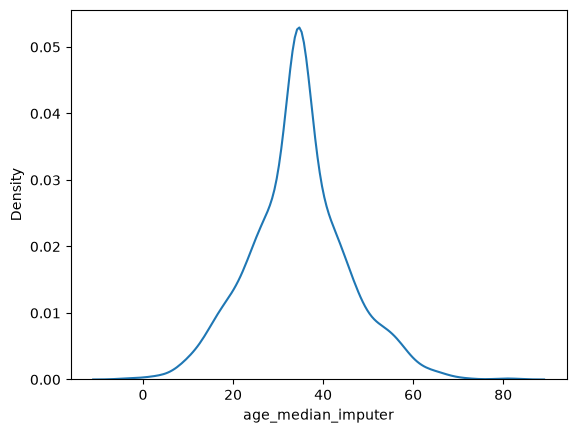

In [78]:
sns.kdeplot(x=df['age_median_imputer'])